# 🔬 U-Net — Segmentation de Fissures
Notebook complet avec entraînement, métriques complètes et visualisations.

## 1. Installation des dépendances

In [1]:
!pip install segmentation-models-pytorch albumentations -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.5 MB/s eta 0:00:00


## 2. Imports

In [2]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import segmentation_models_pytorch as smp

print('✅ Imports OK')

✅ Imports OK


## 3. Configuration

In [3]:
# ── Chemins ──────────────────────────────────────────────
IMAGES_DIR = "/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images"
MASKS_DIR  = "/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks"
CHECKPOINT_DIR = "checkpoints"

# ── Hyperparamètres ───────────────────────────────────────
IMG_SIZE    = 512
BATCH_SIZE  = 8
NUM_EPOCHS  = 200
LR          = 1e-4
PATIENCE    = 20      
THRESHOLD   = 0.5    

# ── Device ───────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print(f'Device : {device}')

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

Device : cuda


In [4]:
mask = cv2.imread('/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_003.jpg', cv2.IMREAD_GRAYSCALE)
print(f'Min: {mask.min()}, Max: {mask.max()}')
print(f'Valeurs uniques: {np.unique(mask)}')

Min: 0, Max: 255
Valeurs uniques: [  0   1   2   3   4   5   6   7   8 248 249 250 251 252 253 254 255]


## 4. Vérification des données

In [5]:
images = os.listdir(IMAGES_DIR)
print(f'Total images : {len(images)}')

missing = []
for img in images:
    name = os.path.splitext(img)[0]
    mask_path = os.path.join(MASKS_DIR, name + '.jpg')
    if not os.path.exists(mask_path):
        missing.append(img)

if missing:
    print(f'❌ Masques manquants ({len(missing)}) :')
    for m in missing[:10]:
        print(' -', m)
else:
    print('✅ Tous les masques sont présents')

Total images : 11298
✅ Tous les masques sont présents


## 5. Split Train / Val / Test

In [6]:
train_imgs, temp_imgs = train_test_split(images, test_size=0.3, random_state=42)
val_imgs, test_imgs   = train_test_split(temp_imgs, test_size=0.5, random_state=42)

print(f'Train : {len(train_imgs)} | Val : {len(val_imgs)} | Test : {len(test_imgs)}')

Train : 7908 | Val : 1695 | Test : 1695


## 6. Augmentations

In [7]:
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=10, p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    # Normalisation ImageNet (important avec poids pré-entraînés)
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

print('✅ Transformations définies')

✅ Transformations définies


## 7. Dataset

In [8]:
class CrackDataset(Dataset):
    def __init__(self, images_dir, masks_dir, image_list, transform=None):
        self.images_dir = images_dir
        self.masks_dir  = masks_dir
        self.images     = image_list
        self.transform  = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):                                          # ← indent corrigée
        name        = self.images[idx]
        name_no_ext = os.path.splitext(name)[0]

        # Chargement image
        img = cv2.imread(os.path.join(self.images_dir, name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Chargement masque en niveaux de gris
        mask = cv2.imread(os.path.join(self.masks_dir, name_no_ext + '.jpg'), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise ValueError(f'Masque introuvable : {name_no_ext}.jpg')

        # 1.0 = fissure (pixel blanc/clair), 0.0 = fond (pixel noir)
        mask_bin = (mask > 127).astype('float32')

        # Augmentation
        if self.transform:
            aug      = self.transform(image=img, mask=mask_bin)
            img      = aug['image']
            mask_bin = aug['mask']

        # HWC → CHW
        img = np.transpose(img, (2, 0, 1))
        return (
            torch.tensor(img,      dtype=torch.float32),
            torch.tensor(mask_bin, dtype=torch.float32).unsqueeze(0)
        )                                                                # ← ')' en double supprimé

train_ds = CrackDataset(IMAGES_DIR, MASKS_DIR, train_imgs, train_transform)
val_ds   = CrackDataset(IMAGES_DIR, MASKS_DIR, val_imgs,   val_transform)
test_ds  = CrackDataset(IMAGES_DIR, MASKS_DIR, test_imgs,  val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f'✅ Datasets prêts — Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')

✅ Datasets prêts — Train: 7908 | Val: 1695 | Test: 1695


## 8. Visualisation d'exemples du dataset

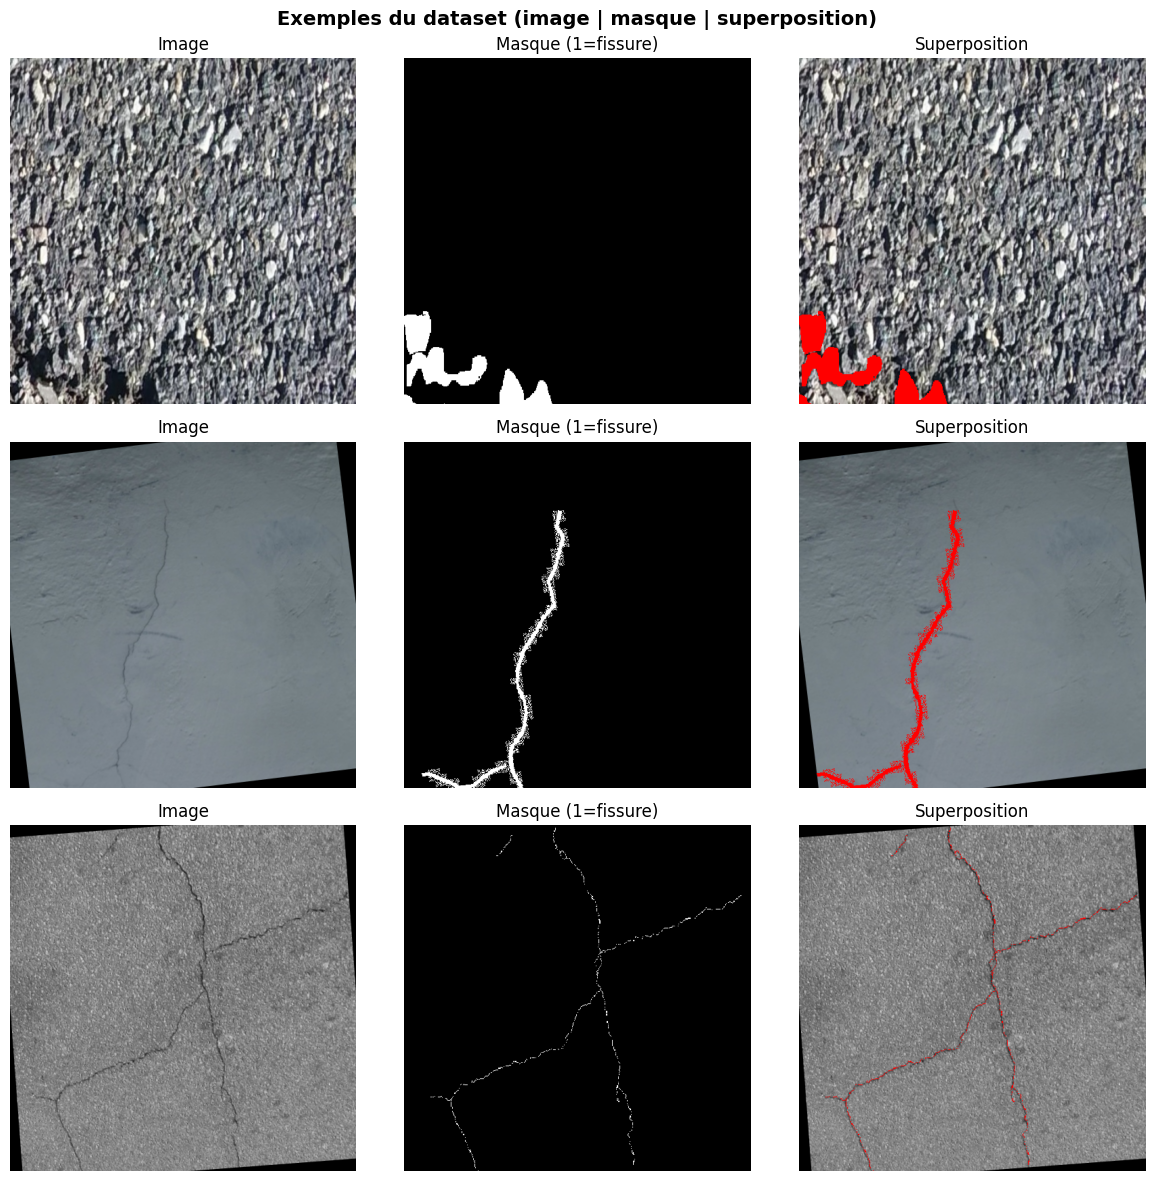

In [9]:
def denormalize(img_tensor):
    """Inverse la normalisation ImageNet pour l'affichage."""
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.numpy().transpose(1, 2, 0)
    img  = std * img + mean
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle('Exemples du dataset (image | masque | superposition)', fontsize=14, fontweight='bold')

for i in range(3):
    img_t, mask_t = train_ds[i]
    img_np  = denormalize(img_t)
    mask_np = mask_t.squeeze().numpy()

    axes[i, 0].imshow(img_np)
    axes[i, 0].set_title('Image')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask_np, cmap='gray')
    axes[i, 1].set_title('Masque (1=fissure)')
    axes[i, 1].axis('off')

    overlay = img_np.copy()
    overlay[mask_np == 1] = [1, 0, 0]  # rouge = fissure
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title('Superposition')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig(f'{CHECKPOINT_DIR}/dataset_examples.png', dpi=150)
plt.show()

## 9. Modèle U-Net

In [10]:
model = smp.Unet(
    encoder_name    = 'resnet34',
    encoder_weights = 'imagenet',
    in_channels     = 3,
    classes         = 1
).to(device)
checkpoint = torch.load("/kaggle/input/models/oussamafroussama/u-net/pytorch/default/1/best_model_epoch083_iou0.5975.pth")

model.load_state_dict(checkpoint['model_state'])
total_params = sum(p.numel() for p in model.parameters())
print(f'✅ Modèle initialisé from scratch (encodeur pré-entraîné ImageNet)')
print(f'   Paramètres totaux : {total_params:,}')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

✅ Modèle initialisé from scratch (encodeur pré-entraîné ImageNet)
   Paramètres totaux : 24,436,369


## 10. Loss, métriques et optimiseur

In [11]:
# ── Loss ─────────────────────────────────────────────────
dice_loss = smp.losses.DiceLoss(mode='binary')
bce_loss  = smp.losses.SoftBCEWithLogitsLoss()

def loss_fn(pred, target):
    """0.8 × DiceLoss + 0.2 × BCE — robuste aux classes déséquilibrées."""
    return 0.8 * dice_loss(pred, target) + 0.2 * bce_loss(pred, target)


# ── Métriques ─────────────────────────────────────────────
def compute_metrics(pred, target, threshold=THRESHOLD):
    """
    Retourne IoU, Dice, Precision, Recall.
    pred   : logits bruts (avant sigmoid)
    target : masque binaire 0/1
    """
    pred_sig = torch.sigmoid(pred)
    pred_bin = (pred_sig > threshold).float()
    tgt_bin  = (target > threshold).float()

    smooth = 1.0
    tp = (pred_bin * tgt_bin).sum()
    fp = (pred_bin * (1 - tgt_bin)).sum()
    fn = ((1 - pred_bin) * tgt_bin).sum()

    iou       = (tp + smooth) / (tp + fp + fn + smooth)
    dice      = (2 * tp + smooth) / (2 * tp + fp + fn + smooth)
    precision = (tp + smooth) / (tp + fp + smooth)
    recall    = (tp + smooth) / (tp + fn + smooth)

    return iou.item(), dice.item(), precision.item(), recall.item()


# ── Optimiseur & Scheduler ────────────────────────────────
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=10, factor=0.5
)

print('✅ Loss, métriques et optimiseur prêts')

✅ Loss, métriques et optimiseur prêts


## 11. Boucle d'entraînement

In [12]:
# ── Historique des métriques ──────────────────────────────
history = {
    'train_loss' : [],
    'val_loss'   : [],
    'val_iou'    : [],
    'val_dice'   : [],
    'val_prec'   : [],
    'val_rec'    : [],
}

best_iou             = 0.0
patience_counter     = 0
best_checkpoint_path = None   # chemin du meilleur checkpoint courant

for epoch in range(NUM_EPOCHS):

    # ── TRAIN ─────────────────────────────────────────────
    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # ── VALIDATION ────────────────────────────────────────
    model.eval()
    val_loss_sum = 0.0
    val_iou_sum  = 0.0
    val_dice_sum = 0.0
    val_prec_sum = 0.0
    val_rec_sum  = 0.0

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)

            val_loss_sum += loss_fn(pred, y).item()
            iou, dice, prec, rec = compute_metrics(pred, y)
            val_iou_sum  += iou
            val_dice_sum += dice
            val_prec_sum += prec
            val_rec_sum  += rec

    n = len(val_loader)
    avg_val_loss = val_loss_sum / n
    avg_val_iou  = val_iou_sum  / n
    avg_val_dice = val_dice_sum / n
    avg_val_prec = val_prec_sum / n
    avg_val_rec  = val_rec_sum  / n

    # ── Sauvegarder l'historique ──────────────────────────
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_iou'].append(avg_val_iou)
    history['val_dice'].append(avg_val_dice)
    history['val_prec'].append(avg_val_prec)
    history['val_rec'].append(avg_val_rec)

    # ── Scheduler ─────────────────────────────────────────
    scheduler.step(avg_val_iou)

    print(
        f'Epoch {epoch+1:3d}/{NUM_EPOCHS} | '
        f'Loss train {avg_train_loss:.4f} val {avg_val_loss:.4f} | '
        f'IoU {avg_val_iou:.4f} | Dice {avg_val_dice:.4f} | '
        f'Prec {avg_val_prec:.4f} | Rec {avg_val_rec:.4f}'
    )

    # ── Gestion des checkpoints versionnés ───────────────
    if avg_val_iou > best_iou:
        # Supprimer l'ancienne version si elle existe
        if best_checkpoint_path is not None and os.path.exists(best_checkpoint_path):
            os.remove(best_checkpoint_path)
            print(f'  🗑️  Ancien checkpoint supprimé : {os.path.basename(best_checkpoint_path)}')

        # Sauvegarder la nouvelle version avec epoch et IoU dans le nom
        best_checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            f'best_model_epoch{epoch+1:03d}_iou{avg_val_iou:.4f}.pth'
        )
        torch.save({
            'epoch'      : epoch + 1,
            'model_state': model.state_dict(),
            'optimizer'  : optimizer.state_dict(),
            'val_iou'    : avg_val_iou,
            'val_dice'   : avg_val_dice,
        }, best_checkpoint_path)

        best_iou         = avg_val_iou
        patience_counter = 0
        print(f'  🔥 Nouveau meilleur modèle : {os.path.basename(best_checkpoint_path)}')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'\n⛔ Early stopping déclenché à l\'epoch {epoch+1}')
            break

print(f'\n✅ Entraînement terminé — Meilleur IoU val : {best_iou:.4f}')
print(f'📦 Checkpoint final : {best_checkpoint_path}')

Epoch   1/200 | Loss train 0.2146 val 0.2282 | IoU 0.5909 | Dice 0.7400 | Prec 0.7339 | Rec 0.7540
  🔥 Nouveau meilleur modèle : best_model_epoch001_iou0.5909.pth
Epoch   2/200 | Loss train 0.2158 val 0.2331 | IoU 0.5846 | Dice 0.7345 | Prec 0.7356 | Rec 0.7427
Epoch   3/200 | Loss train 0.2183 val 0.2318 | IoU 0.5858 | Dice 0.7358 | Prec 0.7411 | Rec 0.7389
Epoch   4/200 | Loss train 0.2138 val 0.2308 | IoU 0.5874 | Dice 0.7369 | Prec 0.7558 | Rec 0.7272
Epoch   5/200 | Loss train 0.2143 val 0.2348 | IoU 0.5817 | Dice 0.7325 | Prec 0.7371 | Rec 0.7368
Epoch   6/200 | Loss train 0.2158 val 0.2341 | IoU 0.5830 | Dice 0.7332 | Prec 0.7319 | Rec 0.7438
Epoch   7/200 | Loss train 0.2138 val 0.2268 | IoU 0.5928 | Dice 0.7414 | Prec 0.7445 | Rec 0.7460
  🗑️  Ancien checkpoint supprimé : best_model_epoch001_iou0.5909.pth
  🔥 Nouveau meilleur modèle : best_model_epoch007_iou0.5928.pth
Epoch   8/200 | Loss train 0.2156 val 0.2309 | IoU 0.5872 | Dice 0.7371 | Prec 0.7146 | Rec 0.7695
Epoch   9/2

## 12. Courbes d'entraînement

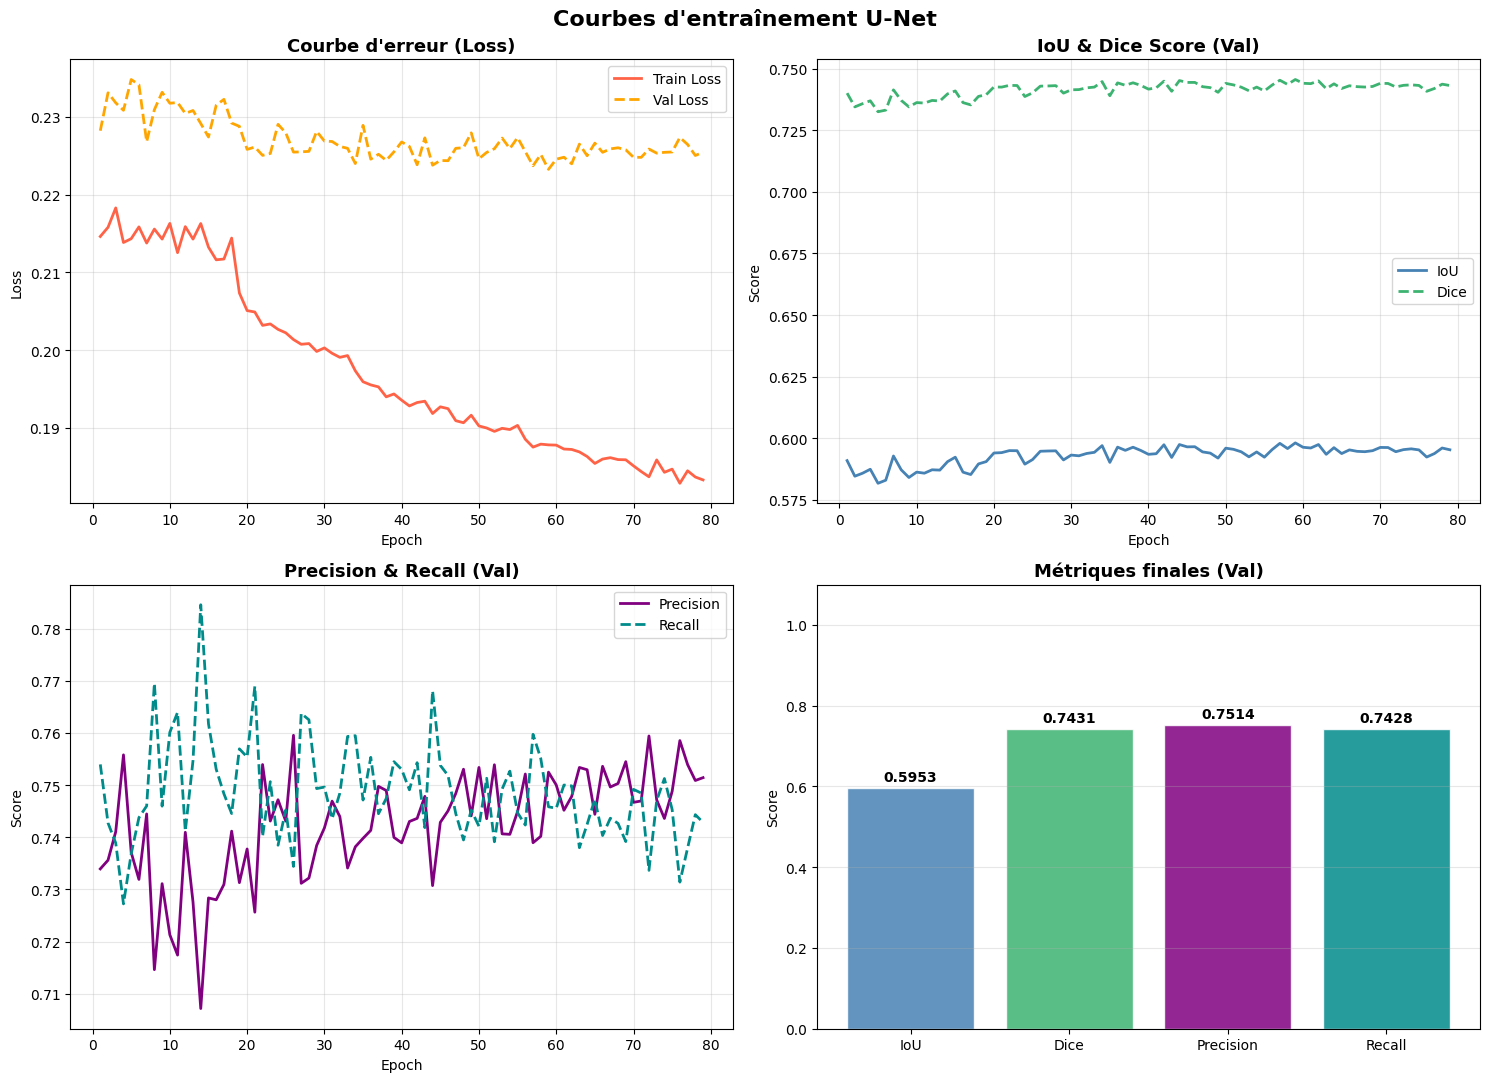

✅ Courbes sauvegardées


In [13]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Courbes d\'entraînement U-Net', fontsize=16, fontweight='bold')

# ── Courbe 1 : Loss ───────────────────────────────────────
ax = axes[0, 0]
ax.plot(epochs_range, history['train_loss'], color='tomato',    linewidth=2, label='Train Loss')
ax.plot(epochs_range, history['val_loss'],   color='orange',    linewidth=2, label='Val Loss',   linestyle='--')
ax.set_title('Courbe d\'erreur (Loss)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend()
ax.grid(True, alpha=0.3)

# ── Courbe 2 : IoU & Dice ─────────────────────────────────
ax = axes[0, 1]
ax.plot(epochs_range, history['val_iou'],  color='steelblue',     linewidth=2, label='IoU')
ax.plot(epochs_range, history['val_dice'], color='mediumseagreen', linewidth=2, label='Dice',  linestyle='--')
ax.set_title('IoU & Dice Score (Val)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Score')
ax.legend()
ax.grid(True, alpha=0.3)

# ── Courbe 3 : Precision & Recall ─────────────────────────
ax = axes[1, 0]
ax.plot(epochs_range, history['val_prec'], color='purple',  linewidth=2, label='Precision')
ax.plot(epochs_range, history['val_rec'],  color='darkcyan', linewidth=2, label='Recall',    linestyle='--')
ax.set_title('Precision & Recall (Val)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Score')
ax.legend()
ax.grid(True, alpha=0.3)

# ── Courbe 4 : Résumé final ───────────────────────────────
ax = axes[1, 1]
final_metrics = {
    'IoU'      : history['val_iou'][-1],
    'Dice'     : history['val_dice'][-1],
    'Precision': history['val_prec'][-1],
    'Recall'   : history['val_rec'][-1],
}
colors = ['steelblue', 'mediumseagreen', 'purple', 'darkcyan']
bars = ax.bar(final_metrics.keys(), final_metrics.values(), color=colors, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, final_metrics.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', va='bottom', fontweight='bold')
ax.set_title('Métriques finales (Val)', fontsize=13, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{CHECKPOINT_DIR}/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Courbes sauvegardées')

## 13. Évaluation sur le jeu de test

In [14]:
# Charger le meilleur checkpoint versionné
print(f'📦 Chargement : {best_checkpoint_path}')
checkpoint = torch.load(best_checkpoint_path, map_location=device)
model.load_state_dict(checkpoint['model_state'])
print(f"   Epoch : {checkpoint['epoch']} | IoU val : {checkpoint['val_iou']:.4f} | Dice val : {checkpoint['val_dice']:.4f}")
model.eval()

test_iou_sum  = 0.0
test_dice_sum = 0.0
test_prec_sum = 0.0
test_rec_sum  = 0.0

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        iou, dice, prec, rec = compute_metrics(pred, y)
        test_iou_sum  += iou
        test_dice_sum += dice
        test_prec_sum += prec
        test_rec_sum  += rec

n = len(test_loader)
print('━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━')
print('  RÉSULTATS FINAUX — JEU DE TEST')
print('━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━')
print(f'  IoU       : {test_iou_sum/n:.4f}')
print(f'  Dice      : {test_dice_sum/n:.4f}')
print(f'  Precision : {test_prec_sum/n:.4f}')
print(f'  Recall    : {test_rec_sum/n:.4f}')
print('━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━')

📦 Chargement : checkpoints/best_model_epoch059_iou0.5981.pth
   Epoch : 59 | IoU val : 0.5981 | Dice val : 0.7456
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  RÉSULTATS FINAUX — JEU DE TEST
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  IoU       : 0.5839
  Dice      : 0.7336
  Precision : 0.7383
  Recall    : 0.7382
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 14. Visualisation des prédictions

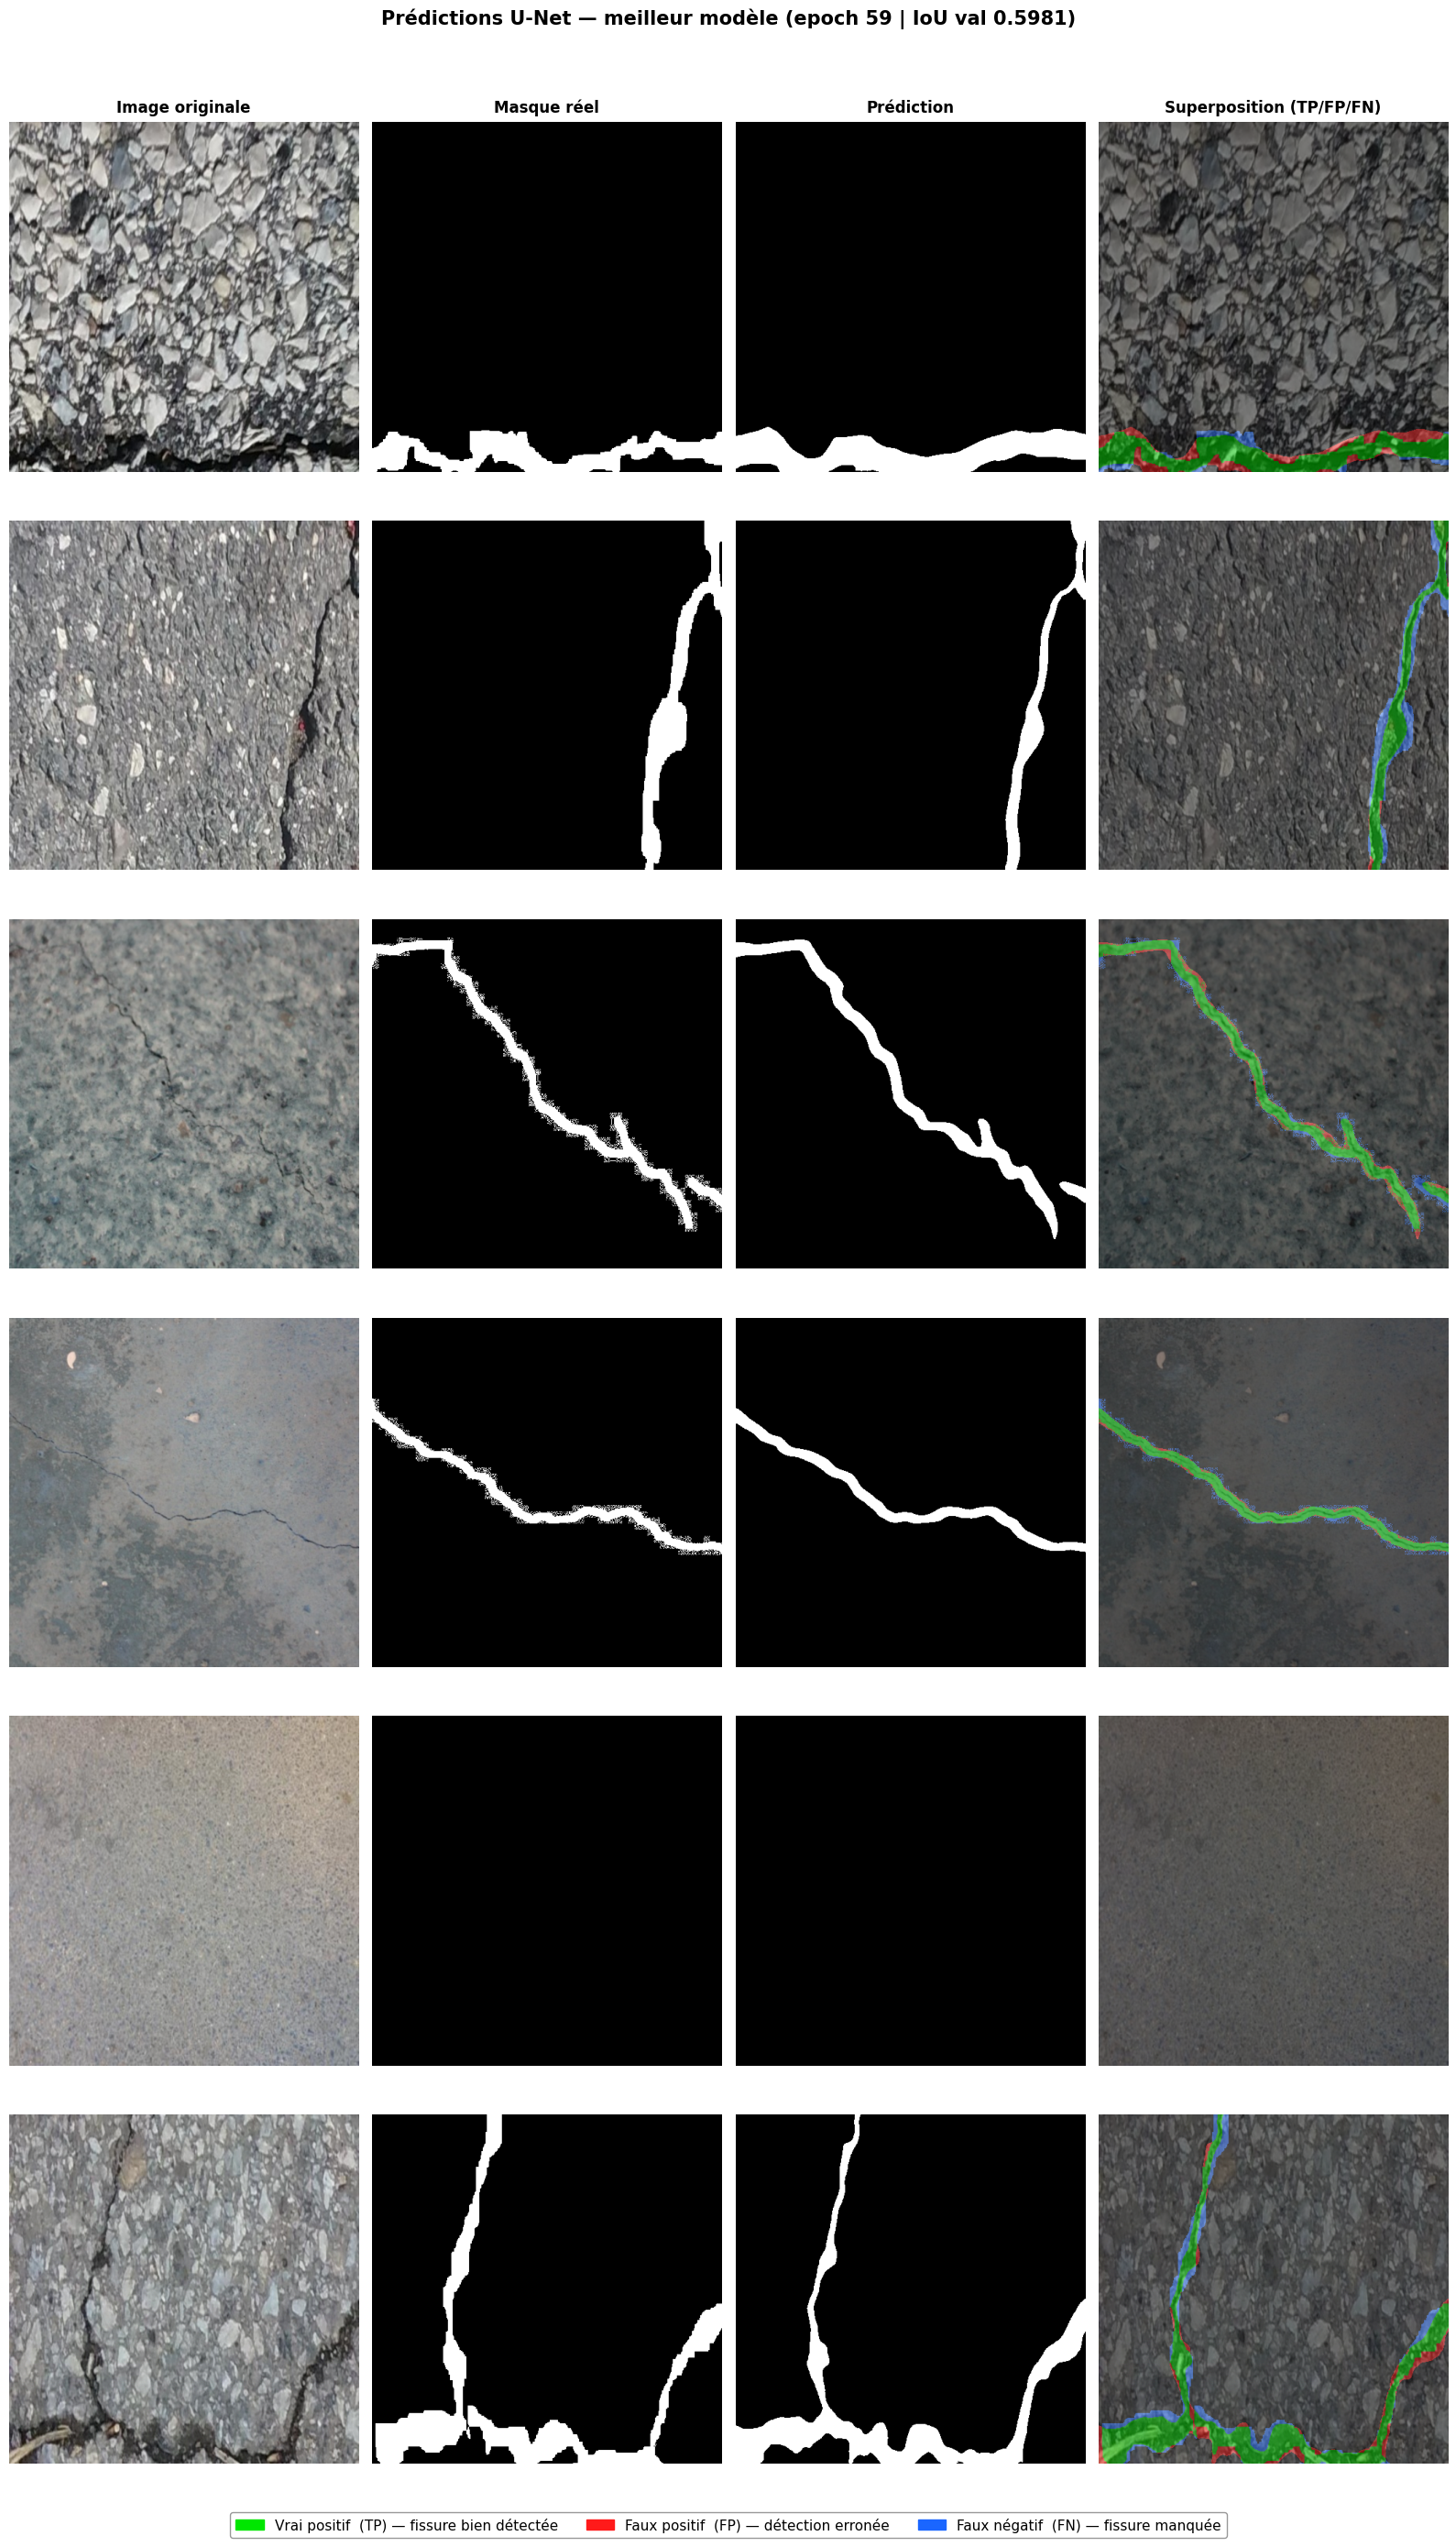

✅ 6 prédictions affichées et sauvegardées dans checkpoints/predictions_test.png


In [15]:
# ── Prédictions sur le jeu de test ──────────────────────
def predict_single(model, dataset, idx, threshold=THRESHOLD):
    """Retourne (image dénormalisée, masque réel, masque prédit, IoU individuel)"""
    img_t, mask_t = dataset[idx]
    with torch.no_grad():
        logit    = model(img_t.unsqueeze(0).to(device))
        pred_bin = (torch.sigmoid(logit) > threshold).float().squeeze().cpu()

    # IoU sur cet exemple
    iou, dice, _, _ = compute_metrics(logit.cpu(), mask_t.unsqueeze(0))

    return denormalize(img_t), mask_t.squeeze().numpy(), pred_bin.numpy(), iou, dice


N_SHOW = 6   # nombre d'images à afficher
indices = list(range(min(N_SHOW, len(test_ds))))

fig, axes = plt.subplots(N_SHOW, 4, figsize=(16, 4.5 * N_SHOW))
fig.suptitle(
    f'Prédictions U-Net — meilleur modèle (epoch {checkpoint["epoch"]} | IoU val {checkpoint["val_iou"]:.4f})',
    fontsize=15, fontweight='bold', y=1.01
)

col_titles = ['Image originale', 'Masque réel', 'Prédiction', 'Superposition (TP/FP/FN)']
for j, title in enumerate(col_titles):
    axes[0, j].set_title(title, fontsize=12, fontweight='bold', pad=8)

for row, idx in enumerate(indices):
    img_np, mask_np, pred_np, iou, dice = predict_single(model, test_ds, idx)

    # Col 0 — Image originale
    axes[row, 0].imshow(img_np)
    axes[row, 0].set_ylabel(f'#{idx}\nIoU={iou:.3f}\nDice={dice:.3f}',
                             fontsize=10, rotation=0, labelpad=55, va='center')
    axes[row, 0].axis('off')

    # Col 1 — Masque réel
    axes[row, 1].imshow(mask_np, cmap='gray', vmin=0, vmax=1)
    axes[row, 1].axis('off')

    # Col 2 — Masque prédit
    axes[row, 2].imshow(pred_np, cmap='gray', vmin=0, vmax=1)
    axes[row, 2].axis('off')

    # Col 3 — Superposition TP / FP / FN
    tp_mask = (pred_np == 1) & (mask_np == 1)
    fp_mask = (pred_np == 1) & (mask_np == 0)
    fn_mask = (pred_np == 0) & (mask_np == 1)

    overlay = np.zeros((*mask_np.shape, 3), dtype=np.float32)
    overlay[tp_mask] = [0.0, 0.9, 0.0]   # vert  — TP
    overlay[fp_mask] = [1.0, 0.1, 0.1]   # rouge — FP
    overlay[fn_mask] = [0.1, 0.4, 1.0]   # bleu  — FN

    blended = np.clip(0.55 * img_np + 0.45 * overlay, 0, 1)
    axes[row, 3].imshow(blended)
    axes[row, 3].axis('off')

# Légende globale
patches = [
    mpatches.Patch(color=(0.0, 0.9, 0.0), label='Vrai positif  (TP) — fissure bien détectée'),
    mpatches.Patch(color=(1.0, 0.1, 0.1), label='Faux positif  (FP) — détection erronée'),
    mpatches.Patch(color=(0.1, 0.4, 1.0), label='Faux négatif  (FN) — fissure manquée'),
]
fig.legend(handles=patches, loc='lower center', ncol=3,
           fontsize=11, bbox_to_anchor=(0.5, -0.015),
           frameon=True, edgecolor='gray')

plt.tight_layout()
plt.savefig(f'{CHECKPOINT_DIR}/predictions_test.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'✅ {N_SHOW} prédictions affichées et sauvegardées dans {CHECKPOINT_DIR}/predictions_test.png')